# SINH DỮ LIỆU TỔNG HỢP CÓ ĐIỀU KIỆN – HOTEL BOOKING DEMAND
**Mục tiêu:** Tạo **một bộ dữ liệu ~200 MB** từ **toàn bộ 119.390 booking gốc** với **32 thuộc tính không đổi**, nhiều bản ghi khác nhau và mức sai lệch thống kê có thể đo lường.


## 1. Cơ sở phương pháp

Phương pháp **sinh dữ liệu tổng hợp có điều kiện** (*Conditional Block Synthesis*) tạo các bản ghi mới từ dữ liệu gốc, đồng thời cố gắng duy trì phân phối thống kê và mối quan hệ giữa các thuộc tính.

Quy trình gồm 4 bước:

1. **Chọn bản ghi gốc (Anchor Sampling):** Chọn ngẫu nhiên một booking làm cơ sở để tạo bản ghi mới.

2. **Kết hợp các nhóm thuộc tính (Conditional Block Recombination):** Thay thế một số nhóm thông tin như khách hàng, loại phòng hoặc kênh đặt phòng bằng dữ liệu từ những booking có đặc điểm tương đồng.

3. **Tạo biến thiên cho dữ liệu số (Local Numerical Synthesis):** Điều chỉnh ngẫu nhiên trong phạm vi nhỏ các giá trị `adr` (giá phòng trung bình) và `lead_time` (số ngày đặt trước), đồng thời bảo đảm các ràng buộc về giá trị và thời gian.

4. **Kiểm tra chất lượng dữ liệu (Quality Gates):** So sánh dữ liệu mới với dữ liệu gốc về phân phối (TVD, KS), tương quan Pearson, tỷ lệ hủy phòng, giá trị thiếu và tỷ lệ bản ghi mới. Đồng thời kiểm tra các ràng buộc để phát hiện dữ liệu không hợp lệ.

**Lưu ý:** Phương pháp chỉ bảo toàn gần đúng các đặc trưng thống kê, không bảo đảm mọi mối quan hệ giữa các thuộc tính đều được giữ nguyên. Vì vậy, cần kiểm định chất lượng sau khi sinh dữ liệu.

## 2. Cấu hình thực nghiệm và thư viện

In [3]:
from pathlib import Path
import json, time, calendar, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

# Có thể thay INPUT_CSV theo nơi lưu dataset.
INPUT_CSV = Path('hotel_bookings.csv')
if not INPUT_CSV.exists():
    INPUT_CSV = Path('/mnt/data/hotel_bookings.csv')
OUTPUT_DIR = Path('hotel_conditional_synthetic_output')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_CSV = OUTPUT_DIR / 'hotel_bookings_synthetic_200MB.csv'
TARGET_MB = 200                          # 1 MB = 1.000.000 byte
TARGET_BYTES = TARGET_MB * 1_000_000
RANDOM_SEED = 42
CHUNK_ROWS = 50_000
# Điều chỉnh tỷ lệ trao đổi khối. Cao hơn -> nhiều tổ hợp mới, có thể tăng sai lệch tương quan.
P_GUEST_SWAP = 0.15
P_SERVICE_SWAP = 0.45
P_CHANNEL_SWAP = 0.35
P_ADR_PERTURB = 0.85
ADR_SIGMA = 0.018                      # ~1.8% độ lệch chuẩn của tỷ lệ giá
P_LEAD_PERTURB = 0.65
MIN_POOL_SIZE = 30                      # nhóm quá hiếm: không tái tổ hợp
# Dùng giá trị vài MB để chạy thử thuật toán trước khi chọn 200 MB.
print('Nguồn:', INPUT_CSV, '| Tồn tại:', INPUT_CSV.exists())

Nguồn: hotel_bookings.csv | Tồn tại: True


## 3. Nạp dữ liệu và xác định loại biến

In [4]:
raw = pd.read_csv(INPUT_CSV)
EXPECTED_COLUMNS = [
    'hotel','is_canceled','lead_time','arrival_date_year','arrival_date_month',
    'arrival_date_week_number','arrival_date_day_of_month','stays_in_weekend_nights',
    'stays_in_week_nights','adults','children','babies','meal','country',
    'market_segment','distribution_channel','is_repeated_guest','previous_cancellations',
    'previous_bookings_not_canceled','reserved_room_type','assigned_room_type',
    'booking_changes','deposit_type','agent','company','days_in_waiting_list',
    'customer_type','adr','required_car_parking_spaces','total_of_special_requests',
    'reservation_status','reservation_status_date'
]
assert raw.columns.to_list() == EXPECTED_COLUMNS, 'Cấu trúc CSV nguồn không khớp 32 cột mong đợi.'
print(f'Nguồn: {len(raw):,} bản ghi x {len(raw.columns)} cột; kích thước {INPUT_CSV.stat().st_size/1e6:.2f} MB')
print('Số hàng giống nhau trong dữ liệu thật:', raw.duplicated().sum())
print(raw.head(3).to_string(index=False))

# Mã định danh số vẫn là biến phân loại, không phải biến liên tục.
CATEGORICAL = [
 'hotel','is_canceled','arrival_date_year','arrival_date_month',
 'arrival_date_week_number','arrival_date_day_of_month','meal','country',
 'market_segment','distribution_channel','is_repeated_guest','reserved_room_type',
 'assigned_room_type','deposit_type','agent','company','customer_type','reservation_status'
]
NUMERIC = [
 'lead_time','adr','stays_in_weekend_nights','stays_in_week_nights',
 'adults','children','babies','previous_cancellations','previous_bookings_not_canceled',
 'booking_changes','days_in_waiting_list','required_car_parking_spaces',
 'total_of_special_requests'
]

Nguồn: 119,390 bản ghi x 32 cột; kích thước 16.86 MB
Số hàng giống nhau trong dữ liệu thật: 31994
       hotel  is_canceled  lead_time  arrival_date_year arrival_date_month  arrival_date_week_number  arrival_date_day_of_month  stays_in_weekend_nights  stays_in_week_nights  adults  children  babies meal country market_segment distribution_channel  is_repeated_guest  previous_cancellations  previous_bookings_not_canceled reserved_room_type assigned_room_type  booking_changes deposit_type  agent  company  days_in_waiting_list customer_type  adr  required_car_parking_spaces  total_of_special_requests reservation_status reservation_status_date
Resort Hotel            0        342               2015               July                        27                          1                        0                     0       2       0.0       0   BB     PRT         Direct               Direct                  0                       0                               0                  C          

## 4. Thiết lập các nhóm thuộc tính và điều kiện kết hợp

Để tạo bản ghi mới, các thuộc tính được chia thành 3 nhóm. Mỗi nhóm chỉ được lấy dữ liệu từ những booking thỏa mãn các điều kiện tương đồng:

1. **Nhóm khách hàng (Guest Block):** Gồm số lượng khách, quốc gia và lịch sử đặt phòng. Các booking phải giống nhau về `hotel`, `is_canceled`, `market_segment` và `customer_type`.

2. **Nhóm dịch vụ/phòng (Service Block):** Gồm loại phòng đặt, loại phòng được cấp và gói bữa ăn. Các booking phải giống nhau về `hotel`, `is_canceled`, `arrival_date_month` và `customer_type`.

3. **Nhóm kênh phân phối (Channel Block):** Gồm kênh đặt phòng, mã đại lý và mã công ty. Các booking phải giống nhau về `hotel`, `is_canceled` và `market_segment`.

**Các thuộc tính được xử lý riêng:**
- **Thời gian và trạng thái đặt phòng:** Giữ nguyên từ bản ghi gốc (Anchor) để tránh tạo ra ngày không hợp lệ hoặc trạng thái hủy không nhất quán.
- **`adr` và `lead_time`:** Được điều chỉnh ngẫu nhiên trong phạm vi nhỏ, có kiểm soát.
- **`agent` và `company`:** Được xem là mã định danh phân loại, không phải giá trị số để tính toán.

**Mục đích:** Tạo ra các booking mới từ những nhóm dữ liệu có đặc điểm tương đồng, đồng thời hạn chế làm thay đổi các mối quan hệ thống kê và ràng buộc nghiệp vụ.

In [5]:
GUEST_BLOCK = ['adults','children','babies','country','is_repeated_guest',
               'previous_cancellations','previous_bookings_not_canceled']
SERVICE_BLOCK = ['reserved_room_type','assigned_room_type','meal']
CHANNEL_BLOCK = ['distribution_channel','agent','company']

GROUP_DEFS = {
 'guest': ['hotel','is_canceled','market_segment','customer_type'],
 'service': ['hotel','is_canceled','arrival_date_month','customer_type'],
 'channel': ['hotel','is_canceled','market_segment']
}

# groupby.indices: ánh xạ group -> vị trí bản ghi trong raw (không phải giá trị ID).
def build_pool(df, columns):
    # Các cột điều kiện không có NA ở bộ Hotel Booking này.
    codes, uniques = pd.factorize(pd.MultiIndex.from_frame(df[columns]), sort=False)
    pools = {}
    for c in np.unique(codes):
        pools[int(c)] = np.flatnonzero(codes == c)
    return codes.astype(np.int32), pools

GROUP_INDEX = {name:build_pool(raw, cols) for name,cols in GROUP_DEFS.items()}
for name, (codes, pools) in GROUP_INDEX.items():
    print(name, 'số nhóm =',len(pools),'nhóm có >= 30 hàng =',sum(len(v)>=MIN_POOL_SIZE for v in pools.values()))

ARRIVAL = pd.to_datetime(
 raw['arrival_date_year'].astype(str)+'-'+raw['arrival_date_month']+'-'+raw['arrival_date_day_of_month'].astype(str),
 format='%Y-%B-%d', errors='coerce'
)
STATUS_DATE = pd.to_datetime(raw['reservation_status_date'], errors='coerce')
assert ARRIVAL.notna().all() and STATUS_DATE.notna().all()
# min_lead = arrival - last status, vì ngày booking phải <= ngày cập nhật trạng thái.
MIN_LEAD = np.maximum(0, (ARRIVAL-STATUS_DATE).dt.days.to_numpy())
assert (raw['lead_time'].to_numpy()>=MIN_LEAD).all(), 'Nguồn có ít nhất một mâu thuẫn booking-date.'
MAX_LEAD = int(raw['lead_time'].max())

guest số nhóm = 91 nhóm có >= 30 hàng = 59
service số nhóm = 182 nhóm có >= 30 hàng = 120
channel số nhóm = 27 nhóm có >= 30 hàng = 26


## 5. Bộ sinh dữ liệu tổng hợp theo khối có điều kiện

In [6]:
rng = np.random.default_rng(RANDOM_SEED)
RAW_N = len(raw)

def sample_peer_positions(anchor_idx, group_name, swap_probability):
    """Chọn booking trong cùng nhóm điều kiện; nhóm nhỏ -> giữ nguyên anchor."""
    codes, pools = GROUP_INDEX[group_name]
    target_codes = codes[anchor_idx]
    result = anchor_idx.copy()
    swap_mask = rng.random(len(anchor_idx)) < swap_probability
    active = np.flatnonzero(swap_mask)
    if len(active) == 0:
        return result
    for c in np.unique(target_codes[active]):
        loc = active[target_codes[active] == c]
        pool = pools[int(c)]
        if len(pool) < MIN_POOL_SIZE:
            continue
        result[loc] = rng.choice(pool, size=len(loc), replace=True)
    return result


def synthesize_chunk(n):
    """Sinh n booking có điều kiện, giữ đúng 32 thuộc tính, không sửa dữ liệu gốc."""
    anchors = rng.integers(0, RAW_N, size=n)
    result = raw.iloc[anchors].reset_index(drop=True).copy()

    for block, group_name, p in [
        (GUEST_BLOCK, 'guest', P_GUEST_SWAP),
        (SERVICE_BLOCK, 'service', P_SERVICE_SWAP),
        (CHANNEL_BLOCK, 'channel', P_CHANNEL_SWAP)
    ]:
        peers = sample_peer_positions(anchors, group_name, p)
        changed = peers != anchors
        if changed.any():
            result.loc[changed, block] = raw.iloc[peers[changed]][block].to_numpy()

    # Biến thiên ADR nhỏ, bảo toàn số 0/âm hiếm (tránh xóa hiện tượng ngoại lệ).
    old_price = result['adr'].to_numpy(dtype=float, copy=True)
    perturb_price = (rng.random(n) < P_ADR_PERTURB) & (old_price > 0) & (old_price <= 1000)
    if perturb_price.any():
        factor = np.exp(rng.normal(-ADR_SIGMA**2/2, ADR_SIGMA, size=perturb_price.sum()))
        new_price = np.round(old_price[perturb_price] * factor, 2)
        result.loc[perturb_price, 'adr'] = np.clip(new_price, 0, 1000)

    # Biến thiên nhỏ lead_time; không để ngày tạo booking sau ngày status.
    old_lead = result['lead_time'].to_numpy(dtype=np.int32, copy=True)
    perturb_lead = rng.random(n) < P_LEAD_PERTURB
    delta = rng.choice([-2, -1, 0, 1, 2], size=n, p=[.07,.23,.40,.23,.07])
    delta[~perturb_lead] = 0
    new_lead = np.clip(old_lead + delta, MIN_LEAD[anchors], MAX_LEAD)
    result['lead_time'] = new_lead.astype('int64')

    return result[EXPECTED_COLUMNS]

# Kiểm tra đầu tiên trên mẫu nhỏ.
preview = synthesize_chunk(5_000)
print('Tổng hợp thí điểm:',preview.shape)
print(preview.head(3).to_string(index=False))

Tổng hợp thí điểm: (5000, 32)
       hotel  is_canceled  lead_time  arrival_date_year arrival_date_month  arrival_date_week_number  arrival_date_day_of_month  stays_in_weekend_nights  stays_in_week_nights  adults  children  babies meal country market_segment distribution_channel  is_repeated_guest  previous_cancellations  previous_bookings_not_canceled reserved_room_type assigned_room_type  booking_changes deposit_type  agent  company  days_in_waiting_list customer_type    adr  required_car_parking_spaces  total_of_special_requests reservation_status reservation_status_date
Resort Hotel            1        101               2017              March                        13                         26                        2                     1       2       0.0       0   BB     PRT         Groups            Corporate                  0                       0                               0                  A                  A                0   Non Refund  495.0      NaN           

## 6. Sinh dữ liệu đến gần 200 MB (ghi CSV theo khối)

Tính dung lượng bằng **byte thực tế**, không suy đoán từ số hàng. Việc ghi theo khối tránh cần giữ toàn bộ 200 MB đồng thời trong RAM. Khi sắp đạt mục tiêu, hoàn tất bằng từng dòng CSV để giới hạn sai số dung lượng (thường dưới chiều dài 1 bản ghi).

In [7]:
# Tái khởi tạo RNG giúp kết quả không phụ thuộc vào việc đã chạy cell xem trước bao nhiêu lần.
rng = np.random.default_rng(RANDOM_SEED)
start = time.time()
output_rows = 0
header_bytes = raw.iloc[:0].to_csv(index=False).encode('utf-8')
with OUTPUT_CSV.open('wb') as f:
    f.write(header_bytes)
    size = len(header_bytes)
    while size < TARGET_BYTES:
        remaining = TARGET_BYTES-size
        # Những khối nhỏ hơn 30KB xử lý ở vòng chốt bên dưới.
        if remaining < 30_000:
            break
        # Số lượng dòng theo ước lượng 145 byte/bản ghi; khống chế kích thước khối.
        guess_rows = min(CHUNK_ROWS, max(1_000, int(remaining/150)))
        block = synthesize_chunk(guess_rows)
        data = block.to_csv(index=False, header=False, float_format='%.2f').encode('utf-8')
        if len(data) <= remaining:
            f.write(data)
            size += len(data)
            output_rows += len(block)
        else:
            for line in data.splitlines(keepends=True):
                if len(line) <= (TARGET_BYTES-size):
                    f.write(line)
                    size += len(line)
                    output_rows += 1
            break
    # Điền phần còn lại bằng một khối nhỏ, chỉ nhận dòng còn phù hợp.
    if TARGET_BYTES-size > 250:
        last = synthesize_chunk(500)
        b = last.to_csv(index=False, header=False, float_format='%.2f').encode('utf-8')
        for line in b.splitlines(keepends=True):
            if len(line) <= TARGET_BYTES-size:
                f.write(line)
                size += len(line)
                output_rows += 1
elapsed = time.time()-start
print(f'Đã ghi {output_rows:,} dòng, {size:,} byte ({size/1e6:.6f} MB), thời gian {elapsed:.1f} giây')
assert OUTPUT_CSV.stat().st_size == size
assert 0 <= TARGET_BYTES-size < 400, 'Sai lệch dung lượng vượt giới hạn kiểm soát.'

Đã ghi 1,383,291 dòng, 199,999,999 byte (199.999999 MB), thời gian 27.2 giây


## 7. Đọc lại sản phẩm và kiểm tra ràng buộc

In [8]:
syn = pd.read_csv(OUTPUT_CSV)
assert syn.columns.to_list() == EXPECTED_COLUMNS
assert len(syn) == output_rows

nonnegative = ['lead_time','stays_in_weekend_nights','stays_in_week_nights',
               'adults','children','babies','previous_cancellations',
               'previous_bookings_not_canceled','booking_changes','days_in_waiting_list',
               'required_car_parking_spaces','total_of_special_requests']

arrival_s = pd.to_datetime(syn['arrival_date_year'].astype(str)+'-'+syn['arrival_date_month']+'-'+
                          syn['arrival_date_day_of_month'].astype(str), format='%Y-%B-%d', errors='coerce')
status_s = pd.to_datetime(syn['reservation_status_date'], errors='coerce')
created_s = arrival_s - pd.to_timedelta(syn['lead_time'], unit='D')

violations = {
    'invalid_arrival_date':int(arrival_s.isna().sum()),
    'invalid_status_date':int(status_s.isna().sum()),
    'creation_after_status':int((created_s > status_s).sum()),
    'negative_counts':int(sum((syn[c].dropna()<0).sum() for c in nonnegative)),
    'cancellation_status_inconsistent':int(((syn['reservation_status']=='Check-Out')!=(syn['is_canceled']==0)).sum()),
}
for c in CATEGORICAL:
    allowed = set(raw[c].dropna().unique().tolist())
    violations[f'unknown_code::{c}'] = int((~syn[c].isin(allowed)&syn[c].notna()).sum())
print('Vi phạm ràng buộc:', {k:v for k,v in violations.items() if v>0} or 'Không')
assert not any(violations.values()), 'Có ràng buộc cứng bị vi phạm.'

# Kiểm tra ngoại lệ đã có từ nguồn: theo dõi, không tùy tiện loại bỏ.
original_anomalies = {
 'zero_guests':int((raw[['adults','children','babies']].fillna(0).sum(axis=1)==0).sum()),
 'zero_nights':int(((raw.stays_in_weekend_nights+raw.stays_in_week_nights)==0).sum()),
 'negative_adr':int((raw.adr<0).sum())
}
print('Ngoại lệ có sẵn trong nguồn:',original_anomalies)

Vi phạm ràng buộc: Không
Ngoại lệ có sẵn trong nguồn: {'zero_guests': 180, 'zero_nights': 715, 'negative_adr': 1}


## 8. Kiểm tra phân phối dữ liệu và giá trị thiếu

So sánh dữ liệu tổng hợp với dữ liệu gốc để đánh giá mức độ bảo toàn phân phối của từng thuộc tính.

- **TVD (Total Variation Distance):** Đo sự khác biệt về tỷ lệ xuất hiện của các giá trị trong biến phân loại.
- **KS (Kolmogorov–Smirnov Distance):** Đo sự khác biệt giữa phân phối của các biến số.
- **Giá trị thiếu:** So sánh tỷ lệ dữ liệu thiếu của từng thuộc tính trước và sau khi sinh.

**Lưu ý:**
- TVD và KS càng gần 0 thì hai phân phối càng tương đồng.
- Các cột `agent`, `company`, `country` được xử lý như biến phân loại.
- Ngưỡng đánh giá được thiết lập cho thực nghiệm, không phải tiêu chuẩn chung cho mọi bộ dữ liệu.

In [9]:
def tvd(a,b):
    pa = a.astype('string').fillna('<NA>').value_counts(normalize=True)
    pb = b.astype('string').fillna('<NA>').value_counts(normalize=True)
    idx = pa.index.union(pb.index)
    return float(0.5 * (pa.reindex(idx,fill_value=0)-pb.reindex(idx,fill_value=0)).abs().sum())

records=[]
for c in EXPECTED_COLUMNS:
    if c in CATEGORICAL or c=='reservation_status_date':
        metric='TVD'; val=tvd(raw[c],syn[c])
    else:
        metric='KS'; val=float(ks_2samp(raw[c].dropna().to_numpy(),syn[c].dropna().to_numpy(),method='asymp').statistic)
    records.append(dict(column=c,metric=metric,distance=val,
                        missing_real=float(raw[c].isna().mean()),
                        missing_synthetic=float(syn[c].isna().mean()),
                        missing_abs_diff=float(abs(raw[c].isna().mean()-syn[c].isna().mean()))))
col_quality = pd.DataFrame(records)
col_quality.to_csv(OUTPUT_DIR/'quality_columns.csv',index=False)
print(col_quality.sort_values('distance',ascending=False).head(12).to_string(index=False))

                   column metric  distance  missing_real  missing_synthetic  missing_abs_diff
                      adr     KS  0.014519      0.000000           0.000000          0.000000
  reservation_status_date    TVD  0.010070      0.000000           0.000000          0.000000
                lead_time     KS  0.004096      0.000000           0.000000          0.000000
                    agent    TVD  0.003193      0.136862           0.136629          0.000233
 arrival_date_week_number    TVD  0.002170      0.000000           0.000000          0.000000
                  country    TVD  0.002116      0.004087           0.004041          0.000046
arrival_date_day_of_month    TVD  0.001842      0.000000           0.000000          0.000000
       arrival_date_month    TVD  0.001300      0.000000           0.000000          0.000000
                  company    TVD  0.001092      0.943069           0.943400          0.000331
       assigned_room_type    TVD  0.000873      0.000000    

## 9. Kiểm tra quan hệ hai biến và tỷ lệ hủy có điều kiện

In [10]:
# Tương quan biến số: Pearson đo phụ thuộc tuyến tính, không bao phủ mọi phụ thuộc phi tuyến.
numerical_corr = [c for c in NUMERIC if c not in ['children']] + ['children']
corr_real = raw[numerical_corr].corr(numeric_only=True)
corr_syn = syn[numerical_corr].corr(numeric_only=True)
diff_corr = (corr_real-corr_syn).abs()
upper = np.triu(np.ones(diff_corr.shape,dtype=bool),1)
corr_max = float(diff_corr.to_numpy()[upper].max())
corr_table = diff_corr.stack().reset_index()
corr_table.columns=['column_a','column_b','abs_corr_diff']
corr_table.to_csv(OUTPUT_DIR/'correlation_drift.csv',index=False)

conditional=[]
for c in ['hotel','market_segment','deposit_type','arrival_date_year','customer_type']:
    left = raw.groupby(c,dropna=False)['is_canceled'].agg(['mean','size'])
    right = syn.groupby(c,dropna=False)['is_canceled'].agg(['mean','size'])
    for cat in left.index:
        if int(left.loc[cat,'size']) < 100:
            continue  # bỏ nhóm quá hiếm khỏi chỉ số tối đa (vẫn có trong phân phối TVD)
        rate_syn = float(right.loc[cat,'mean']) if cat in right.index else float('nan')
        conditional.append(dict(group_column=c, group_value=str(cat),
                                n_real=int(left.loc[cat,'size']),
                                rate_real=float(left.loc[cat,'mean']),
                                rate_synthetic=rate_syn,
                                abs_rate_diff=abs(float(left.loc[cat,'mean'])-rate_syn)))
cond_table = pd.DataFrame(conditional)
cond_table.to_csv(OUTPUT_DIR/'conditional_cancellation.csv',index=False)
print('Sai lệch tương quan Pearson lớn nhất:',round(corr_max,6))
print('Sai lệch tỷ lệ hủy theo nhóm lớn nhất:',round(float(cond_table.abs_rate_diff.max()),6))

Sai lệch tương quan Pearson lớn nhất: 0.033158
Sai lệch tỷ lệ hủy theo nhóm lớn nhất: 0.005829


## 10. Kiểm tra tính mới của dữ liệu (Novelty)

Kiểm tra mức độ khác biệt giữa các bản ghi tổng hợp và dữ liệu gốc thông qua hai chỉ số:

1. **Full-row Novelty:** Tỷ lệ bản ghi tổng hợp không trùng hoàn toàn với bất kỳ bản ghi gốc nào trên cả 32 thuộc tính.

2. **Structural Novelty:** Tỷ lệ bản ghi tổng hợp không trùng với dữ liệu gốc khi bỏ hai thuộc tính `adr` và `lead_time`. Chỉ số này giúp xác định dữ liệu có thực sự tạo ra tổ hợp mới hay chỉ thay đổi nhẹ hai giá trị số.

**Phương pháp kiểm tra:** Lấy ngẫu nhiên 100.000 bản ghi tổng hợp để so sánh với toàn bộ dữ liệu gốc, sử dụng mã băm (hash) nhằm tăng tốc độ xử lý.

**Lưu ý:**
- Tỷ lệ tính mới càng cao cho thấy càng nhiều bản ghi khác với dữ liệu gốc.
- Kết quả chỉ là ước lượng trên mẫu 100.000 bản ghi, không phải toàn bộ dữ liệu.
- Bản ghi mới không đồng nghĩa với thông tin thống kê độc lập hoặc bảo đảm quyền riêng tư.

In [11]:
NOVELTY_N = min(100_000, len(syn))
novel_sample = syn.sample(n=NOVELTY_N, random_state=RANDOM_SEED).copy()

def novel_rate(exclude=()):
    columns = [c for c in EXPECTED_COLUMNS if c not in exclude]
    h_orig = pd.util.hash_pandas_object(raw[columns],index=False).to_numpy(dtype=np.uint64)
    h_syn = pd.util.hash_pandas_object(novel_sample[columns],index=False).to_numpy(dtype=np.uint64)
    return float(1-np.isin(h_syn,np.unique(h_orig)).mean())

novel_full = novel_rate()
novel_structure = novel_rate(('adr','lead_time'))
print(f'Ước lượng dòng khác hẳn nguồn (32 cột): {novel_full:.2%} | n={NOVELTY_N:,}')
print(f'Ước lượng tổ hợp cấu trúc mới (loại trừ 2 biến nhiễu): {novel_structure:.2%}')
print(f'Tỷ lệ trùng bên trong mẫu synthetic: {novel_sample.duplicated().mean():.2%}')

Ước lượng dòng khác hẳn nguồn (32 cột): 95.09% | n=100,000
Ước lượng tổ hợp cấu trúc mới (loại trừ 2 biến nhiễu): 51.76%
Tỷ lệ trùng bên trong mẫu synthetic: 0.70%


## 11. Báo cáo chất lượng và biểu đồ đối chiếu

{
  "novel_full_row_rate_sample_estimate": 0.95087,
  "novel_structure_rate_excluding_adr_lead_time_sample_estimate": 0.51763,
  "max_univariate_distance": 0.014518702797991667,
  "max_TVD": 0.010069685459131842,
  "max_KS": 0.014518702797991667,
  "max_missing_rate_abs_diff": 0.0003312618738993134,
  "max_abs_pearson_correlation_diff": 0.03315834791094979,
  "max_conditional_cancellation_rate_abs_diff_min_n_100": 0.005829161907061536
}


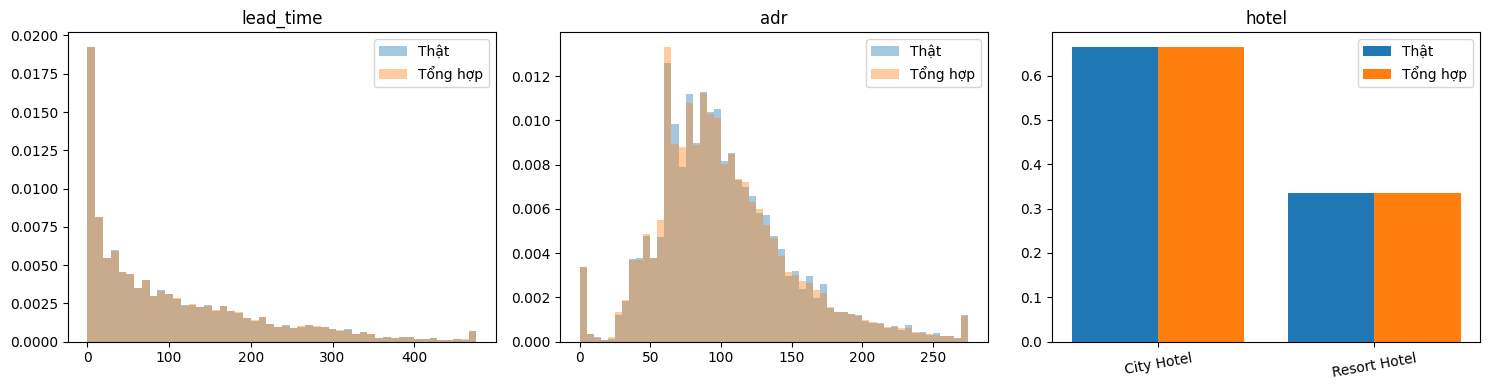

In [12]:
report = {
    'input_file':str(INPUT_CSV),
    'output_file':str(OUTPUT_CSV),
    'method':'Stratified Conditional Block Resampling + Constrained Numeric Perturbation',
    'seed':RANDOM_SEED,
    'input_rows':int(len(raw)), 'output_rows':int(len(syn)),
    'input_columns':int(raw.shape[1]), 'output_columns':int(syn.shape[1]),
    'target_bytes':int(TARGET_BYTES),'actual_bytes':int(OUTPUT_CSV.stat().st_size),
    'novelty_estimation_sample_rows':NOVELTY_N,
    'novel_full_row_rate_sample_estimate':novel_full, 'novel_structure_rate_excluding_adr_lead_time_sample_estimate':novel_structure,
    'max_univariate_distance':float(col_quality.distance.max()),
    'max_TVD':float(col_quality.loc[col_quality.metric=='TVD','distance'].max()),
    'max_KS':float(col_quality.loc[col_quality.metric=='KS','distance'].max()),
    'max_missing_rate_abs_diff':float(col_quality.missing_abs_diff.max()),
    'max_abs_pearson_correlation_diff':corr_max,
    'max_conditional_cancellation_rate_abs_diff_min_n_100':float(cond_table.abs_rate_diff.max()),
    'hard_constraint_violations':violations,
    'source_anomaly_counts':original_anomalies,
    'disclaimer':'Rows are statistically dependent simulations; do not treat as independent actual new bookings or use total values as historical totals.'
}
with (OUTPUT_DIR/'quality_report.json').open('w',encoding='utf8') as f:
    json.dump(report,f,indent=2,ensure_ascii=False)
print(json.dumps({k:v for k,v in report.items() if k.startswith('max_') or k.startswith('novel_')},indent=2,ensure_ascii=False))

fig,axs=plt.subplots(1,3,figsize=(15,4))
for ax,c,bins in zip(axs,['lead_time','adr','hotel'],[50,55,None]):
    if bins:
        lo,hi = np.quantile(raw[c].dropna(),[.001,.995])
        ax.hist(raw[c].clip(lo,hi),bins=bins,density=True,alpha=.4,label='Thật')
        ax.hist(syn[c].clip(lo,hi),bins=bins,density=True,alpha=.4,label='Tổng hợp')
    else:
        pr=raw[c].value_counts(normalize=True)
        ps=syn[c].value_counts(normalize=True)
        names=pr.index.tolist(); x=np.arange(len(names))
        ax.bar(x-.2,pr.reindex(names),width=.4,label='Thật')
        ax.bar(x+.2,ps.reindex(names),width=.4,label='Tổng hợp')
        ax.set_xticks(x);ax.set_xticklabels(names,rotation=10)
    ax.set_title(c);ax.legend()
plt.tight_layout()
fig.savefig(OUTPUT_DIR/'distribution_comparison.png',dpi=160)
plt.show()

## 12. Đánh giá chất lượng dữ liệu tổng hợp

Kiểm tra các chỉ số chất lượng và so sánh với ngưỡng đã thiết lập để xác định dữ liệu tổng hợp có đạt yêu cầu hay không.

- **Nếu đạt:** Dữ liệu đáp ứng các tiêu chí kiểm định đã đặt ra, nhưng không bảo đảm mọi mối quan hệ giữa 32 thuộc tính đều được giữ nguyên.
- **Nếu không đạt:** Điều chỉnh giảm tỷ lệ kết hợp các nhóm thuộc tính, giảm mức nhiễu `ADR_SIGMA`.

**Lưu ý:** Sau mỗi lần điều chỉnh, cần kiểm định lại và không bỏ qua các chỉ số không đạt yêu cầu.

In [13]:
GATES = {
 'hard_constraints_zero':all(v==0 for v in violations.values()),
 'full_row_novelty_at_least_0.95':novel_full>=0.95,
 'structure_novelty_at_least_0.30':novel_structure>=0.30,
 'max_TVD_at_most_0.03':report['max_TVD']<=0.03,
 'max_KS_at_most_0.03':report['max_KS']<=0.03,
 'max_corr_drift_at_most_0.07':corr_max<=0.07,
 'max_conditional_rate_diff_at_most_0.05':cond_table.abs_rate_diff.max()<=0.05,
}
GATES = {k: bool(v) for k,v in GATES.items()}
print(pd.Series(GATES).to_string())
report['quality_gates']=GATES
with (OUTPUT_DIR/'quality_report.json').open('w',encoding='utf8') as f:
    json.dump(report,f,indent=2,ensure_ascii=False)
if not all(GATES.values()):
    print('CẢNH BÁO: Ít nhất một chỉ tiêu chưa đạt; xem báo cáo trước khi dùng dữ liệu.')
else:
    print('Tất cả chỉ tiêu nghiệm thu thiết lập trước đều đạt.')

hard_constraints_zero                     True
full_row_novelty_at_least_0.95            True
structure_novelty_at_least_0.30           True
max_TVD_at_most_0.03                      True
max_KS_at_most_0.03                       True
max_corr_drift_at_most_0.07               True
max_conditional_rate_diff_at_most_0.05    True
Tất cả chỉ tiêu nghiệm thu thiết lập trước đều đạt.
